# 3. Time Series Forecasting: Cumulative GitHub Stars

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import warnings

import os
import hashlib
import seaborn as sns
warnings.filterwarnings("ignore")


# Check for GPU and set device
if torch.cuda.is_available():
    device_name = torch.cuda.get_device_name(0)
    device = torch.device("cuda")
    print(f"Using GPU: {device_name}")
else:
    device = torch.device("cpu")
    print("No GPU detected. Using CPU.")


# Fix seed for reproducible randomization.
username = "sudhanva.joshi"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print(f"Seed generated: {seed}")
rng = np.random.default_rng(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
    

# Ensure global numpy random state is seeded (for statsmodels/sklearn internals)
np.random.seed(seed)

# Ensure strict determinism for GPU operations (if available)
if torch.cuda.is_available():
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Set environment variable for certain hash-based operations in Python
os.environ["PYTHONHASHSEED"] = str(seed)

print(f"Global seeds and deterministic backends set using seed: {seed}")
    
sns.set_theme(context="paper", style="darkgrid",
              palette="magma", font="Nimbus Roman")
def add_username_to_plot(ax, userid=username):
    """Add the username watermark to a matplotlib plot."""
    # Using the exact code from the assignment PDF
    ax.text(
        0.95, -0.1,
        userid,
        ha='right', va='bottom',
        transform=ax.transAxes,
        fontsize=10, color='gray', alpha=0.7
    )

Using GPU: NVIDIA GeForce GTX 1650
Seed generated: 1027714457
Global seeds and deterministic backends set using seed: 1027714457


## 3.1 Dataset Description


## 3.2 Single Repository Evaluation
The *CONFIG* setup gives me control over any 2 repositories that I want to work with.

In [2]:
CONFIG = {
    'seq_length': 50,        # Lookback window for DL models (p in the recurrence)
    'forecast_horizon': 14,  # h for autoregressive forecasting
    'train_ratio': 0.8,
    'batch_size': 64,
    'epochs': 100,
    'learning_rate': 0.001,
    'hidden_dim': 32,
    # Choosing two distinct repos: React and Flask
    # 'guys, please use the react and flask repo data for the 3rd question' - Sairam, circa 2025
    'repos_to_analyze': ['facebook/react', 'pallets/flask'] 
}

### 3.2.1 Preprocessing and Feature Engineering

In [3]:
class TimeSeriesDataHandler:
    """
    Handles data loading, preprocessing, splitting, and normalization for a specific repository.
    Task 3.2.1: Clean, align, and normalize.
    """
    def __init__(self, csv_path, repo_id, seq_length):
        self.csv_path = csv_path
        self.repo_id = repo_id
        self.seq_length = seq_length
        self.scaler = MinMaxScaler(feature_range=(0, 1))
        
        self.dates = None
        self.cumulative_series = None
        self.incremental_series = None
        self.train_norm = None
        self.test_norm = None
        self.test_cumulative_start = None
        self.test_cumulative_gt = None # Ground Truth for test
        
    def load_and_process(self):
            """Loads data, fills missing dates, and converts to incremental domain."""
            # 1. Load
            df = pd.read_csv(self.csv_path)
            df['timestamp'] = pd.to_datetime(df['timestamp'])
            
            # Filter specific repo
            repo_df = df[df['repository_id'] == self.repo_id].sort_values('timestamp')
            
            # The dataset has an artifact where stars cap at 4000. 
            # We truncate the time series strictly BEFORE it hits this 
            # cap to avoid training on the artificial flatline.
            if (repo_df['stars'] >= 4000).any():
                # Find the first timestamp where it hits 4000
                cutoff_row = repo_df[repo_df['stars'] >= 4000].iloc[0]
                cutoff_date = cutoff_row['timestamp']
                
                print(f"Truncating {self.repo_id} at {cutoff_date} (hit 4000 stars limit).")
                # Keep data strictly before this date
                repo_df = repo_df[repo_df['timestamp'] < cutoff_date]
            
            # 2. Handle missing points (Task 3.2.1.1)
            full_range = pd.date_range(start=repo_df['timestamp'].min(), end=repo_df['timestamp'].max(), freq='D')
            repo_df = repo_df.set_index('timestamp').reindex(full_range)
            
            # Interpolate strictly (stars don't disappear usually, but missing days need filling)
            repo_df['stars'] = repo_df['stars'].interpolate(method='linear').astype(int)
            
            self.dates = repo_df.index
            self.cumulative_series = repo_df['stars'].values
            
            # 3. Convert to Incremental Domain (Task 3.2.1.2)
            # Modeling daily gains is stationary; modeling cumulative sum is not.
            self.incremental_series = np.diff(self.cumulative_series, prepend=self.cumulative_series[0])
            
            return self.dates, self.cumulative_series, self.incremental_series


    def create_splits(self, train_ratio=0.8):
        """Splits data chronologically (Task 3.2.1.4)."""
        data_len = len(self.incremental_series)
        train_size = int(data_len * train_ratio)
        
        # Split on incremental data
        train_raw = self.incremental_series[:train_size].reshape(-1, 1)
        test_raw = self.incremental_series[train_size:].reshape(-1, 1)
        
        # 4. Normalize (Task 3.2.1.3) - Fit on TRAIN only to avoid leakage
        self.scaler.fit(train_raw)
        self.train_norm = self.scaler.transform(train_raw).flatten()
        self.test_norm = self.scaler.transform(test_raw).flatten()
        
        # Store values needed to reconstruct cumulative paths later
        self.test_cumulative_start = self.cumulative_series[train_size-1]
        self.test_cumulative_gt = self.cumulative_series[train_size:]
        
        return self.train_norm, self.test_norm

    def create_sequences(self, data):
        """Sliding window for RNN/CNN (Sequence -> Target)."""
        xs, ys = [], []
        for i in range(len(data) - self.seq_length):
            x = data[i : i + self.seq_length]
            y = data[i + self.seq_length]
            xs.append(x)
            ys.append(y)
        return np.array(xs), np.array(ys)

    def inverse_transform(self, data):
        return self.scaler.inverse_transform(data.reshape(-1, 1)).flatten()
        
    def plot_data_overview(self):
            """Visualizes cumulative vs incremental trends."""
            fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
            
            # 1. Plotting
            ax1.plot(self.dates, self.cumulative_series, color='#2c3e50')
            ax1.set_title(f"{self.repo_id}: Cumulative Growth")
            ax1.set_ylabel("Total Stars")
            add_username_to_plot(ax1)
            
            ax2.plot(self.dates, self.incremental_series, color='#e67e22', alpha=0.8, lw=0.8)
            ax2.set_title(f"{self.repo_id}: Daily New Stars")
            ax2.set_ylabel("New Stars/Day")
            add_username_to_plot(ax2)
            
            # Defined my start and end dates.
            # start_date = pd.Timestamp('2016-01-01')
            end_date = pd.Timestamp('2014-03-01') 
            # Apply limits to the X-axis
            ax1.set_xlim(right=end_date)
            
            plt.tight_layout()
            plt.show()

### 3.2.2 Forecasting Models

In [4]:
# Cell 3: 3.2.2 Deep Learning Models

class RNNForecaster(nn.Module):
    """
    Simple RNN for Time Series Forecasting.
    Architecture: Input -> RNN Layer -> Fully Connected -> Output
    """
    def __init__(self, input_size=1, hidden_size=64, num_layers=1):
        super(RNNForecaster, self).__init__()
        self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # x shape: (batch, seq_len, input_size)
        out, _ = self.rnn(x)
        # Take the output from the last time step
        last_out = out[:, -1, :]
        prediction = self.fc(last_out)
        return prediction

class CNNForecaster(nn.Module):
    """
    1D CNN for Time Series Forecasting.
    Architecture: Input -> Conv1d -> ReLU -> MaxPool -> Flatten -> FC -> Output
    """
    def __init__(self, seq_length, num_channels=1):
        super(CNNForecaster, self).__init__()
        self.conv1 = nn.Conv1d(in_channels=num_channels, out_channels=64, kernel_size=3, padding=1)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(kernel_size=2)
        
        # Calculate size after pooling
        # Length goes from seq_length -> seq_length // 2
        flattened_size = 64 * (seq_length // 2)
        self.fc = nn.Linear(flattened_size, 1)

    def forward(self, x):
        # x shape: (batch, seq_len, input_size) -> needs (batch, input_size, seq_len) for Conv1d
        x = x.permute(0, 2, 1)
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)
        
        # .view() requires contiguous memory. .reshape() works regardless.
        x = x.reshape(x.size(0), -1)
        
        x = self.fc(x)
        return x

### 3.2.3 Evaluation Protocol

In [5]:
def train_model(model, loader, criterion, optimizer, epochs=100):
    model.train()
    loss_log = []
    for epoch in range(epochs):
        epoch_loss = 0
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            pred = model(X_batch)
            loss = criterion(pred, y_batch)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        loss_log.append(epoch_loss / len(loader))
    return loss_log

def autoregressive_forecast(model, data_handler, horizon):
    """
    Generates predictions for t+1, t+2... t+horizon using model outputs as new inputs.
    """
    model.eval()
    preds_norm = []
    
    # Start with the last known sequence from training data
    curr_seq = data_handler.train_norm[-data_handler.seq_length:]
    
    with torch.no_grad():
        for _ in range(horizon):
            # Prepare input tensor (Batch=1)
            input_tensor = torch.FloatTensor(curr_seq).view(1, -1, 1).to(device)
            
            # Predict next increment
            pred = model(input_tensor).item()
            preds_norm.append(pred)
            
            # Update sequence: drop first, add predicted
            curr_seq = np.append(curr_seq[1:], pred)
            
    # Inverse scale to get actual daily increments
    preds_inc = data_handler.inverse_transform(np.array(preds_norm))
    
    # Reconstruct cumulative sum: Last Train Val + CumSum(Predicted Increments)
    preds_cum = data_handler.test_cumulative_start + np.cumsum(preds_inc)
    return preds_cum


def fit_arma(data_handler, horizon):
    """Fits statsmodels ARMA on training data."""
    # Note: We use trend='c' because MinMax data is not centered at 0.
    try:
        # Try a standard order with a constant trend
        model = ARIMA(data_handler.train_norm, order=(5, 0, 5), trend='c')
        model_fit = model.fit()
    except:
        # Fallback to a simpler model if convergence fails
        print("ARMA (5,0,5) failed, falling back to (2,0,2)")
        model = ARIMA(data_handler.train_norm, order=(2, 0, 2), trend='c')
        model_fit = model.fit()
        
    # Forecast normalized steps
    fc_norm = model_fit.forecast(steps=horizon)
    
    # Inverse transform to get back to star counts
    fc_inc = data_handler.inverse_transform(fc_norm)
    
    # Reconstruct cumulative sum
    fc_cum = data_handler.test_cumulative_start + np.cumsum(fc_inc)
    
    return fc_cum

## 3.3 Report & Reproducibility

Processing Repository facebook/react.

Truncating facebook/react at 2014-02-12 00:00:00 (hit 4000 stars limit).


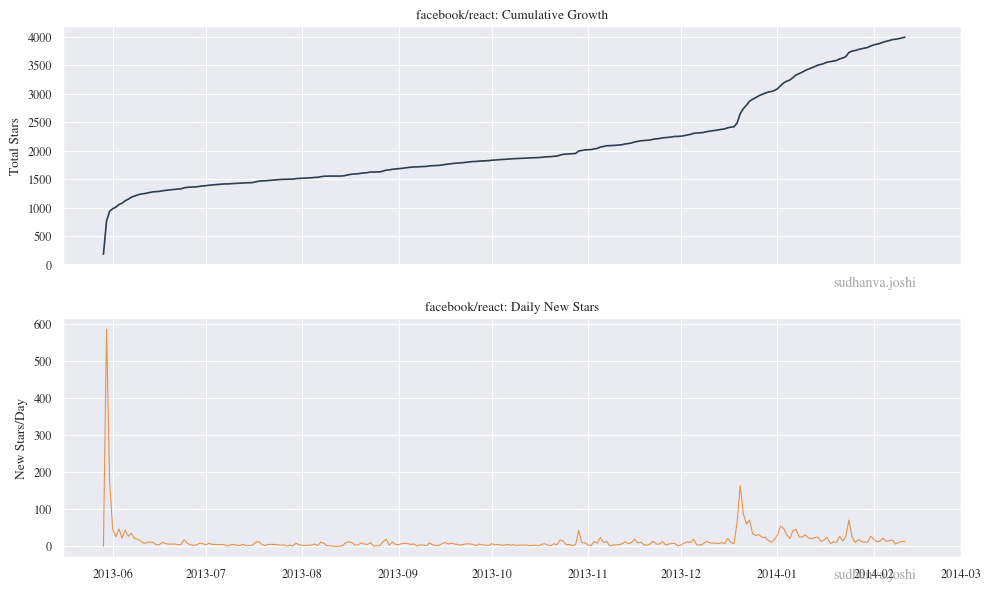

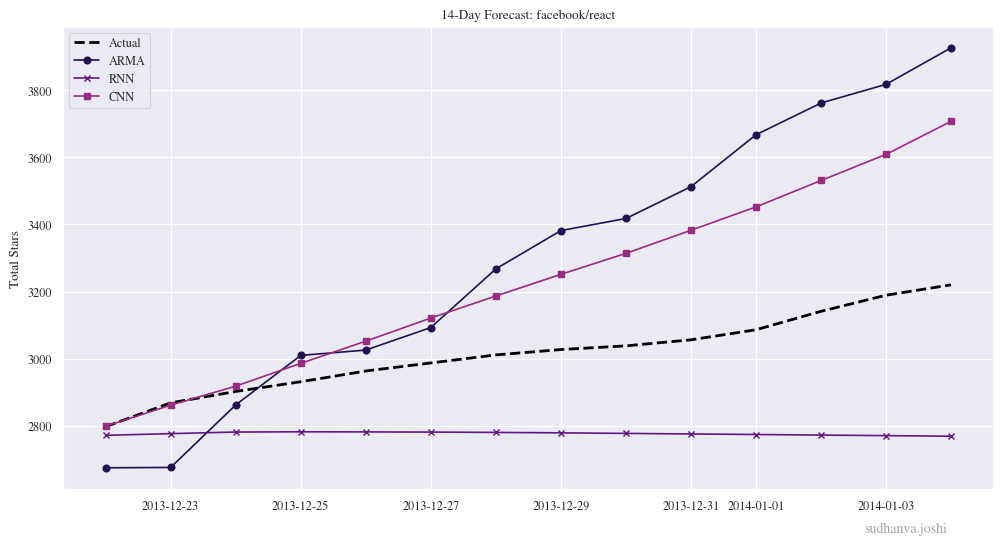

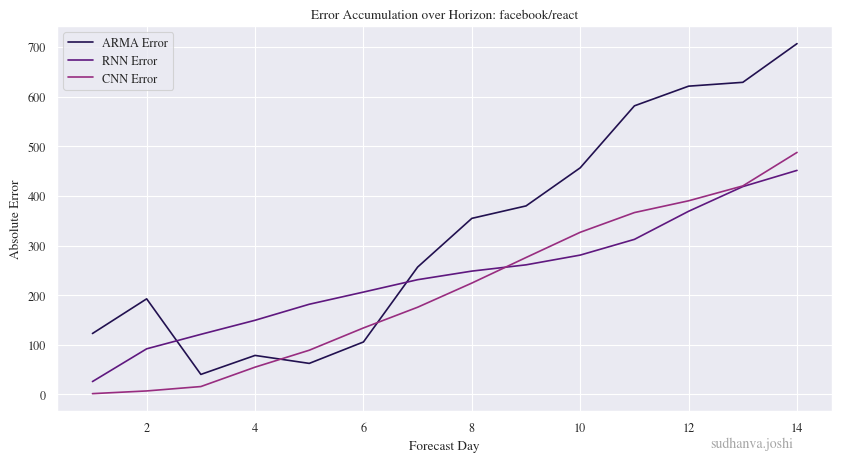

Processing Repository pallets/flask.

Truncating pallets/flask at 2012-12-15 00:00:00 (hit 4000 stars limit).


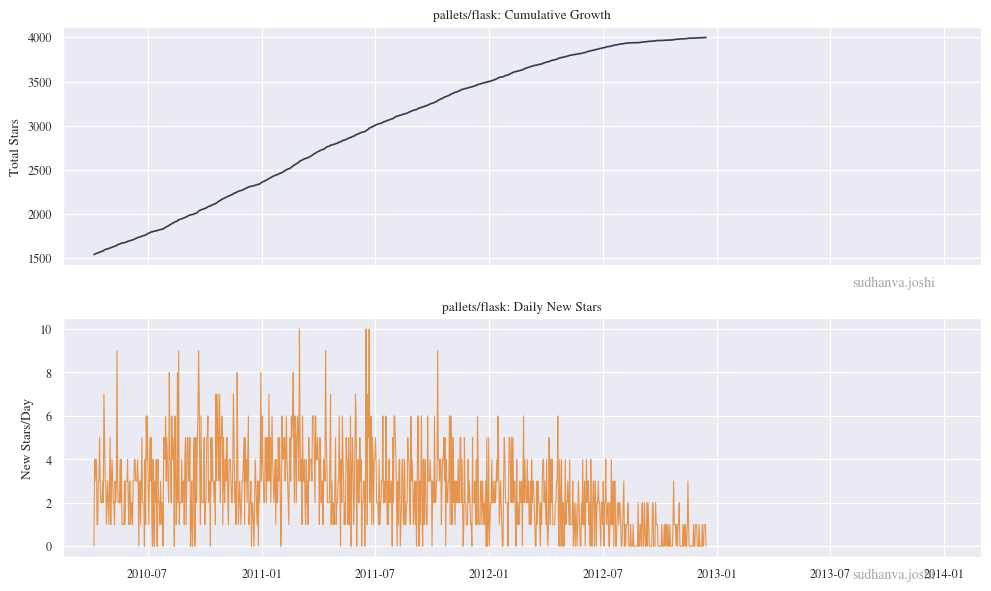

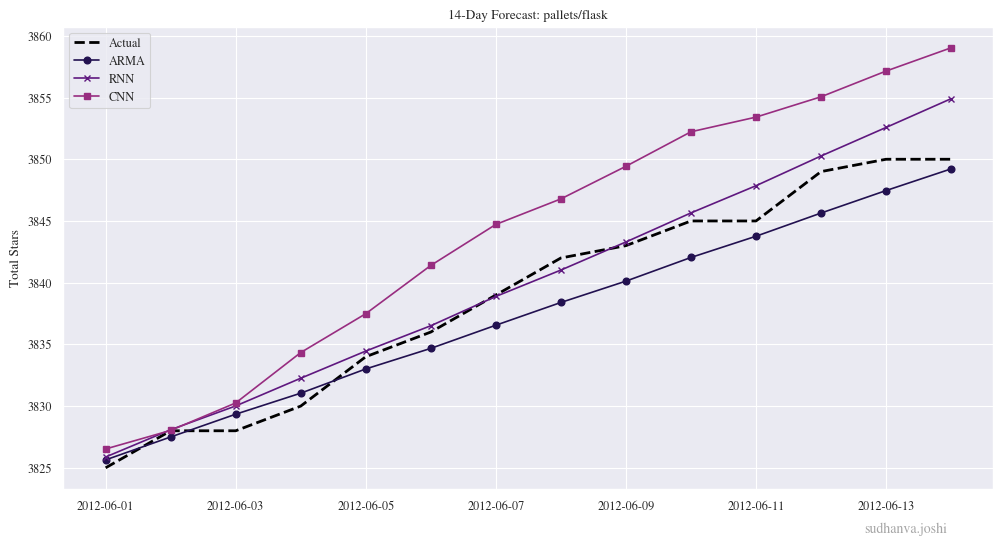

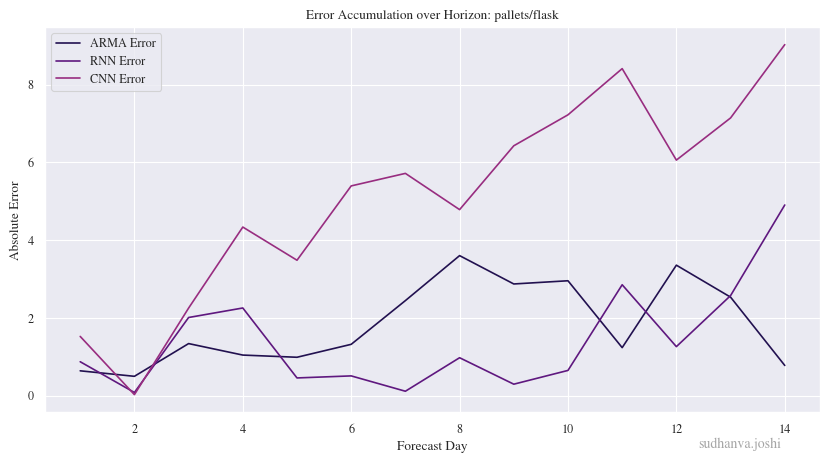


Repository           | Model  | MAE        | RMSE      
------------------------------------------------------------
facebook/react       | ARMA   | 327.75      | 399.91
facebook/react       | RNN    | 239.21      | 266.81
facebook/react       | CNN    | 212.05      | 266.45
pallets/flask        | ARMA   | 1.83      | 2.11
pallets/flask        | RNN    | 1.42      | 1.93
pallets/flask        | CNN    | 5.13      | 5.71


In [6]:
final_metrics = {}

for repo in CONFIG['repos_to_analyze']:
    print(f"Processing Repository {repo}.\n")
    
    # 1. Data Prep
    handler = TimeSeriesDataHandler('./data/Q3/stars_data.csv', repo, CONFIG['seq_length'])
    dates, _, _ = handler.load_and_process()
    handler.plot_data_overview()
    
    train_norm, test_norm = handler.create_splits(CONFIG['train_ratio'])
    
    # 2. Prepare Tensors
    X_np, y_np = handler.create_sequences(train_norm)
    X_t = torch.FloatTensor(X_np).unsqueeze(-1) # Add feature dim
    y_t = torch.FloatTensor(y_np).unsqueeze(-1)
    
    dataset = TensorDataset(X_t, y_t)
    loader = DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=True)
    
    # 3. Initialize & Train Models
    # RNN
    rnn = RNNForecaster(input_size=1, hidden_size=CONFIG['hidden_dim']).to(device)
    opt_rnn = optim.AdamW(rnn.parameters(), lr=CONFIG['learning_rate'])
    train_model(rnn, loader, nn.MSELoss(), opt_rnn, CONFIG['epochs'])
    
    # CNN
    cnn = CNNForecaster(seq_length=CONFIG['seq_length']).to(device)
    opt_cnn = optim.AdamW(cnn.parameters(), lr=CONFIG['learning_rate'])
    train_model(cnn, loader, nn.MSELoss(), opt_cnn, CONFIG['epochs'])
    
    # 4. Forecast
    horizon = CONFIG['forecast_horizon']
    pred_rnn = autoregressive_forecast(rnn, handler, horizon)
    pred_cnn = autoregressive_forecast(cnn, handler, horizon)
    pred_arma = fit_arma(handler, horizon)
    
    # 5. Evaluate
    # Get Ground Truth for the specific horizon window
    gt_cum = handler.test_cumulative_gt[:horizon]
    
    # Metrics Helper
    def calc_metrics(pred, true):
        return {
            'MAE': mean_absolute_error(true, pred),
            'RMSE': np.sqrt(mean_squared_error(true, pred))
        }
        
    metrics = {
        'ARMA': calc_metrics(pred_arma, gt_cum),
        'RNN': calc_metrics(pred_rnn, gt_cum),
        'CNN': calc_metrics(pred_cnn, gt_cum)
    }
    final_metrics[repo] = metrics
    
    # 6. Visualization
    plt.figure(figsize=(12, 6))
    # Dates for forecast
    start_idx = len(handler.train_norm)
    date_slice = handler.dates[start_idx : start_idx + horizon]
    
    plt.plot(date_slice, gt_cum, 'k--', linewidth=2, label='Actual')
    plt.plot(date_slice, pred_arma, marker='o', label='ARMA')
    plt.plot(date_slice, pred_rnn, marker='x', label='RNN')
    plt.plot(date_slice, pred_cnn, marker='s', label='CNN')
    
    plt.title(f"14-Day Forecast: {repo}")
    plt.ylabel("Total Stars")
    plt.legend()
    add_username_to_plot(plt.gca())
    plt.show()
    
    # 7. Error Growth Analysis (Task 3.2.3 bullet 2)
    plt.figure(figsize=(10, 5))
    days = np.arange(1, horizon + 1)
    plt.plot(days, np.abs(pred_arma - gt_cum), label='ARMA Error')
    plt.plot(days, np.abs(pred_rnn - gt_cum), label='RNN Error')
    plt.plot(days, np.abs(pred_cnn - gt_cum), label='CNN Error')
    plt.title(f"Error Accumulation over Horizon: {repo}")
    plt.xlabel("Forecast Day")
    plt.ylabel("Absolute Error")
    plt.legend()
    add_username_to_plot(plt.gca())
    plt.show()

# Print Summary Table
print("\n" + "="*60)
print(f"{'Repository':<20} | {'Model':<6} | {'MAE':<10} | {'RMSE':<10}")
print("-" * 60)
for repo, m_dict in final_metrics.items():
    for model_name, scores in m_dict.items():
        print(f"{repo:<20} | {model_name:<6} | {scores['MAE']:.2f}      | {scores['RMSE']:.2f}")